In [2]:
import pandas as pd 
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, accuracy_score,r2_score,confusion_matrix

df = pd.read_excel("week10_students.xlsx")
df.to_csv("week10_students.csv",index= False)



In [3]:
## Exercise 1.1

print(f"shape:",df.shape)
print(df[["quiz_avg","assignments_avg","attendance_pct"]].corrwith(df["score"]).round(3));

# Most useful feature: quiz_avg (r = 0.80), clearly stronger than assignments_avg (0.54).
# attendance_pct is weakest (0.24), so on its own it says little about the final score.

shape: (150, 9)
quiz_avg           0.801
assignments_avg    0.536
attendance_pct     0.238
dtype: float64


In [4]:
# Exercise 1.2  Frame and Split 

features = ["quiz_avg","assignments_avg","attendance_pct"]
X = df[features]
y = df["score"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=42);

print("Train:",len(X_train)) 
print("Test:",len(X_test))

# We hide 25% of students so we can test the model on students it has never seen.
# Scoring on the data it learned from would only measure memorisation; the hidden
# set gives an honest estimate of how it will do on future, new students.

Train: 112
Test: 38


In [5]:
# Part 2  Regression and Predict Score
# Exercise 2.1  Train and Read the model

model = LinearRegression();
reg = model.fit(X_train,y_train)
for name, coef in zip(features,reg.coef_):
    print(f"{name:16s} {coef:.3f}")
print("intercept      ", round (reg.intercept_,3))

# One extra quiz point is worth about +0.58 exam points, holding assignments and
# attendance fixed (10 more quiz points is about 5.8 more exam points).




quiz_avg         0.579
assignments_avg  0.365
attendance_pct   0.113
intercept       -4.428


In [6]:
## Exercises 2.2
## Judge it honestly 

pred = reg.predict(X_test)
mae = mean_absolute_error(y_test,pred)
r2 =r2_score(y_test,pred)

print(f"MAE: {mae:.2f} points | R2 :{r2:.2f}")

# MAE (dean's language): on students the model had never seen, its predicted score
# is off by about 3.3 points on average (out of 100).
# R2 (dean's language): the three inputs explain roughly 89% of the differences
# between students' scores; the remaining ~11% is down to things we did not measure.


MAE: 3.33 points | R2 :0.89


In [7]:
## Predict New Student 
new = pd.DataFrame({"quiz_avg": [70], "assignments_avg": [75], "attendance_pct": [90]})
print("New student predicted score:", round(reg.predict(new)[0], 1))

me = pd.DataFrame({"quiz_avg":[80],"assignments_avg":[85],"attendance_pct":[100]})
print("New Predicted score :",round(reg.predict(me)[0],1))

New student predicted score: 73.7
New Predicted score : 84.2


In [8]:
## Part 3  Classification 
## Build the target and train

df["passed"] = (df["score"] >=50).astype(int)
print(df["passed"].value_counts())

yc = df["passed"]
Xc_train,Xc_test,yc_train,yc_test = train_test_split(X,yc,test_size=0.25,random_state=42)
clf = LogisticRegression(max_iter = 1000).fit(Xc_train,yc_train)





passed
1    131
0     19
Name: count, dtype: int64


In [9]:
## The Accuracy Trap 

acc = accuracy_score(yc_test,clf.predict(Xc_test))
print("Model Accuracy : ", round(acc,3))
print("Lazy line Base :",round(yc_test.mean(),3))
print (confusion_matrix (yc_test,clf.predict(Xc_test)))

# Not useless. Both score 89.5% because only 4 of 38 test students failed, so "everyone
# passes" is right 34/38 times -- but it catches 0 of the 4 failing students, which are
# exactly the ones we care about. The confusion matrix shows our model correctly flags 3
# of the 4 failing students (and misses 1). The price is 3 false alarms (students who
# would pass but were flagged), which an advisor can cheaply check. Accuracy hides this
# because the classes are imbalanced (131 pass vs 19 fail); recall on the at-risk class
# is the metric that matters.



Model Accuracy :  0.895
Lazy line Base : 0.895
[[ 3  1]
 [ 3 31]]


In [10]:
##  Part 4: Feature Engineering 

def test_r2(Xs):
    a,b,c,d = train_test_split(Xs,y,test_size=0.25,random_state=42)
    return r2_score(d,LinearRegression().fit(a,c).predict(b))
    
res = pd.DataFrame({
    "version": ["1. quiz_avg only", "2. all three numeric", "3. three + program (one-hot)"],
    "test_R2": [test_r2(df[["quiz_avg"]]),
                test_r2(df[features]),
                test_r2(pd.get_dummies(df[features + ["program"]], columns=["program"]))]
}).round(3)
print(res.to_string(index=False))

# Helped: adding assignments and attendance (0.62 -> 0.89), a big jump because they carry
# information the quizzes do not. Did not help: adding program (0.89 -> 0.88); it
# adds 3 extra columns but no new signal, so it slightly hurts on unseen data.
# Lesson: more information helps only when it is relevant. More columns is not always better.

                     version  test_R2
            1. quiz_avg only    0.624
        2. all three numeric    0.887
3. three + program (one-hot)    0.880


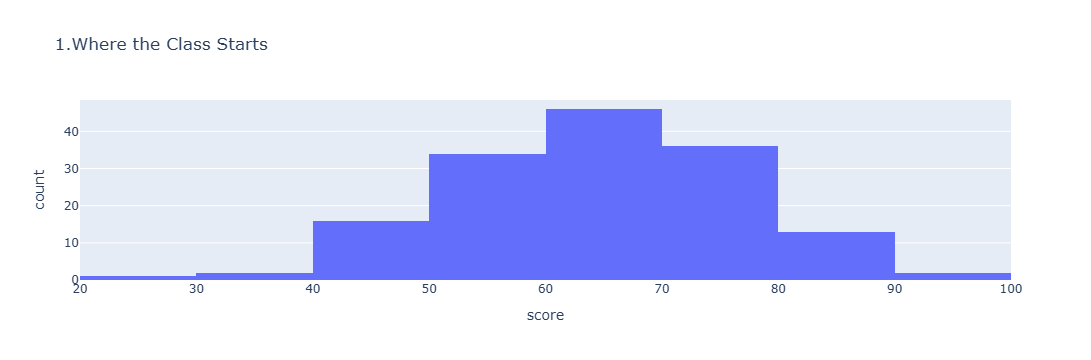

In [11]:
##Part 5: Ship a Dashbord 
fig1 = px.histogram (df, x="score",nbins=12,title= "1.Where the Class Starts")
fig1.show()


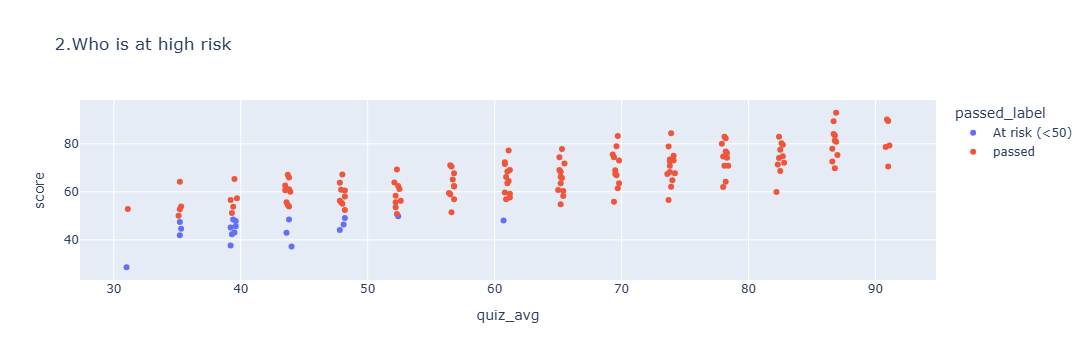

In [13]:
df["passed_label"] = df["passed"].map({1:"passed",0: "At risk (<50)"})
fig2 = px.scatter(df,x="quiz_avg",y= "score",color = "passed_label",hover_name ="name",title = "2.Who is at high risk")
fig2.show();

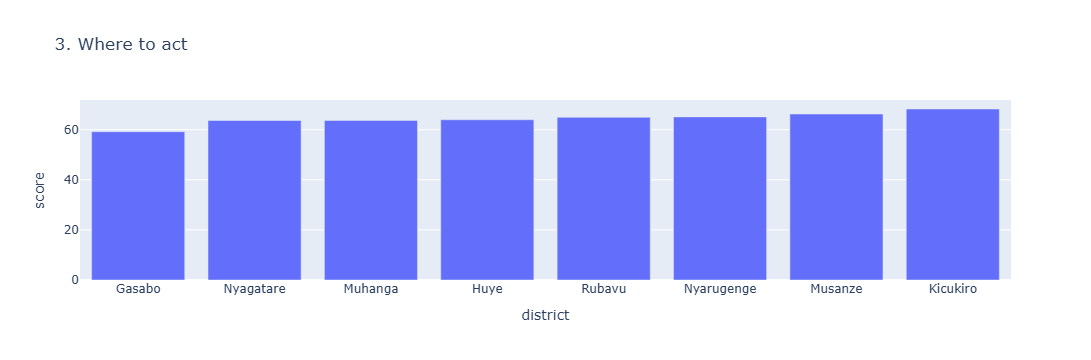

In [16]:
district_avg = df.groupby("district",as_index=False )["score"].mean().sort_values("score")
fig3 = px.bar(district_avg, x="district", y="score", title="3. Where to act")
fig3.show()
##fig2.write_html("class_dashboard.html")

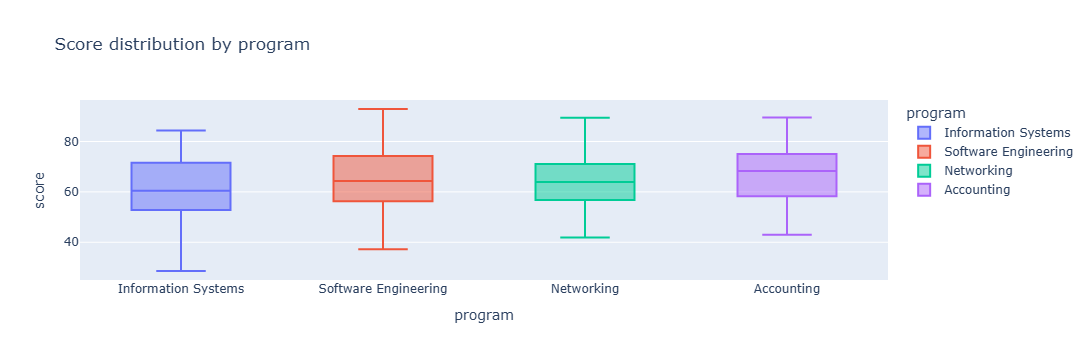

In [17]:
## Bonus  : One chart four stories 
figb = px.box(df, x="program", y="score", color="program", title="Score distribution by program")
figb.show()


In [ ]:
# Networking is the most consistent (smallest spread, SD about 10.8); Software Engineering
# has the widest spread (SD about 13.8, scores from 37 to 93).\